# Real Estate Housing Price Prediction
## Ridge & Lasso Regression

### Project Overview
This project aims to predict median house values using the California Housing dataset.

The project involves exploratory data analysis, data preprocessing, feature engineering, and the implementation of multiple regression models.

### Objectives
- Explore and understand the California Housing dataset.
- Handle missing values and categorical variables.
- Perform feature engineering and investigate multicollinearity.
- Implement Ordinary Least Squares (OLS), Ridge, and Lasso Regression.
- Optimize model hyperparameters using GridSearchCV.
- Evaluate and compare models using RMSE, MAE, and R².
- Analyze prediction errors through residual visualizations.

### Technologies Used
Python, Pandas, NumPy, Matplotlib, Seaborn, and Scikit-learn.


In [1]:
# ==========================================
# 1. IMPORT REQUIRED LIBRARIES
# ==========================================

# Data manipulation and numerical operations
import numpy as np
import pandas as pd

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Data preprocessing
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Regression models
from sklearn.linear_model import LinearRegression, Ridge, Lasso

# Model evaluation metrics
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

# Display settings
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)
pd.set_option('display.float_format', '{:.3f}'.format)

# Visualization settings
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

print("All required libraries imported successfully!")


All required libraries imported successfully!


## 2. Loading the Dataset

The California Housing dataset is loaded into a Pandas DataFrame for further analysis.

The dataset contains information about housing characteristics, population, household statistics, geographical location, and median house values.


In [2]:
# ==========================================
# 2.1 LOAD THE DATASET
# ==========================================

from pathlib import Path

# Locate the dataset from common notebook working directories
possible_paths = [
    Path("../dataset/housing.csv"),
    Path("dataset/housing.csv"),
    Path("Task_2_Housing_Price_Prediction/dataset/housing.csv")
]

dataset_path = next(
    (path for path in possible_paths if path.exists()),
    None
)

if dataset_path is None:
    raise FileNotFoundError(
        "housing.csv not found. Please check the dataset folder."
    )

# Load the CSV file
df = pd.read_csv(dataset_path)

print("Dataset loaded successfully!")
print(f"Dataset location: {dataset_path}")


Dataset loaded successfully!
Dataset location: ..\dataset\housing.csv



### 2.2 Previewing the Dataset

The first five records are displayed to understand how the data is organized and to examine the available features.


In [3]:

# Display the first five rows
df.head()


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.230,37.880,41.000,880.000,129.000,322.000,126.000,8.325,452600.000,NEAR BAY
1,-122.220,37.860,21.000,7099.000,1106.000,2401.000,1138.000,8.301,358500.000,NEAR BAY
2,-122.240,37.850,52.000,1467.000,190.000,496.000,177.000,7.257,352100.000,NEAR BAY
3,-122.250,37.850,52.000,1274.000,235.000,558.000,219.000,5.643,341300.000,NEAR BAY
4,-122.250,37.850,52.000,1627.000,280.000,565.000,259.000,3.846,342200.000,NEAR BAY



### 2.3 Dataset Dimensions

The shape attribute is used to determine the number of observations and features present in the dataset.


In [4]:

# Display the number of rows and columns
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])
print("Dataset dimensions:", df.shape)


Number of rows: 20640
Number of columns: 10
Dataset dimensions: (20640, 10)



### 2.4 Dataset Information

The column names and data types are examined to distinguish between numerical and categorical variables.


In [5]:

# Display column names
print("Column Names:")
print(df.columns.tolist())

# Display dataset information
print("\nDataset Information:")
df.info()


Column Names:
['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'median_house_value', 'ocean_proximity']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  str    
dtypes: float64(9), str(1)
memory usage: 1.7 MB



### 2.5 Descriptive Statistical Summary

Descriptive statistics are generated to understand the distribution of numerical features, including their mean, standard deviation, minimum, maximum, and quartile values.


In [6]:

# Generate descriptive statistics
df.describe()


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000,20640.000,20640.000,20640.000,20433.000,20640.000,20640.000,20640.000,20640.000
mean,-119.570,35.632,28.639,2635.763,537.871,1425.477,499.540,3.871,206855.817
std,2.004,2.136,12.586,2181.615,421.385,1132.462,382.330,1.900,115395.616
min,-124.350,32.540,1.000,2.000,1.000,3.000,1.000,0.500,14999.000
25%,-121.800,33.930,18.000,1447.750,296.000,787.000,280.000,2.563,119600.000
50%,-118.490,34.260,29.000,2127.000,435.000,1166.000,409.000,3.535,179700.000
75%,-118.010,37.710,37.000,3148.000,647.000,1725.000,605.000,4.743,264725.000
max,-114.310,41.950,52.000,39320.000,6445.000,35682.000,6082.000,15.000,500001.000



### 2.6 Missing Value Analysis

The dataset is examined for missing values to identify columns that require data imputation during preprocessing.


In [7]:

# Count missing values in each column
missing_values = df.isnull().sum()

# Calculate missing value percentages
missing_percentage = (missing_values / len(df)) * 100

# Create a summary table
missing_summary = pd.DataFrame({
    'Missing Values': missing_values,
    'Missing Percentage': missing_percentage
})

missing_summary


,Missing Values,Missing Percentage
longitude,0,0.000
latitude,0,0.000
housing_median_age,0,0.000
total_rooms,0,0.000
total_bedrooms,207,1.003
population,0,0.000
households,0,0.000
median_income,0,0.000
median_house_value,0,0.000
ocean_proximity,0,0.000



### 2.7 Duplicate Record Analysis

The dataset is checked for duplicate observations to identify repeated records that may affect the analysis.


In [8]:

# Count duplicate rows
duplicate_count = df.duplicated().sum()

print("Number of duplicate records:", duplicate_count)


Number of duplicate records: 0



### 2.8 Categorical Feature Analysis

The unique categories and their frequency distribution are examined for the ocean_proximity feature.


In [9]:

# Display unique categories
print("Unique ocean proximity categories:")
print(df['ocean_proximity'].unique())

# Display category frequencies
print("\nCategory Distribution:")
print(df['ocean_proximity'].value_counts())


Unique ocean proximity categories:
<ArrowStringArray>
['NEAR BAY', '<1H OCEAN', 'INLAND', 'NEAR OCEAN', 'ISLAND']
Length: 5, dtype: str

Category Distribution:
ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5
Name: count, dtype: int64



### 2.9 Initial Dataset Observations

The initial inspection of the California Housing dataset revealed the following:

1. The dataset contains 20,640 observations and 10 columns.
2. It consists of 9 numerical features and 1 categorical feature.
3. The target variable for prediction is `median_house_value`.
4. The `total_bedrooms` column contains 207 missing values.
5. The `ocean_proximity` feature contains multiple categorical values that require encoding.
6. The dataset requires further preprocessing before regression modeling.

These observations will guide the exploratory data analysis and preprocessing stages.



# 3. Exploratory Data Analysis (EDA)

Exploratory Data Analysis is performed to understand the underlying patterns, distributions, relationships, and characteristics of the California Housing dataset.

This analysis helps identify important features, potential outliers, correlations, and geographical trends that may influence median house values.



### 3.1 Distribution of Numerical Features

Histograms are used to examine the distributions of numerical variables in the dataset.

This analysis helps identify skewed distributions, variations in feature ranges, and potential irregularities that may influence regression modeling.


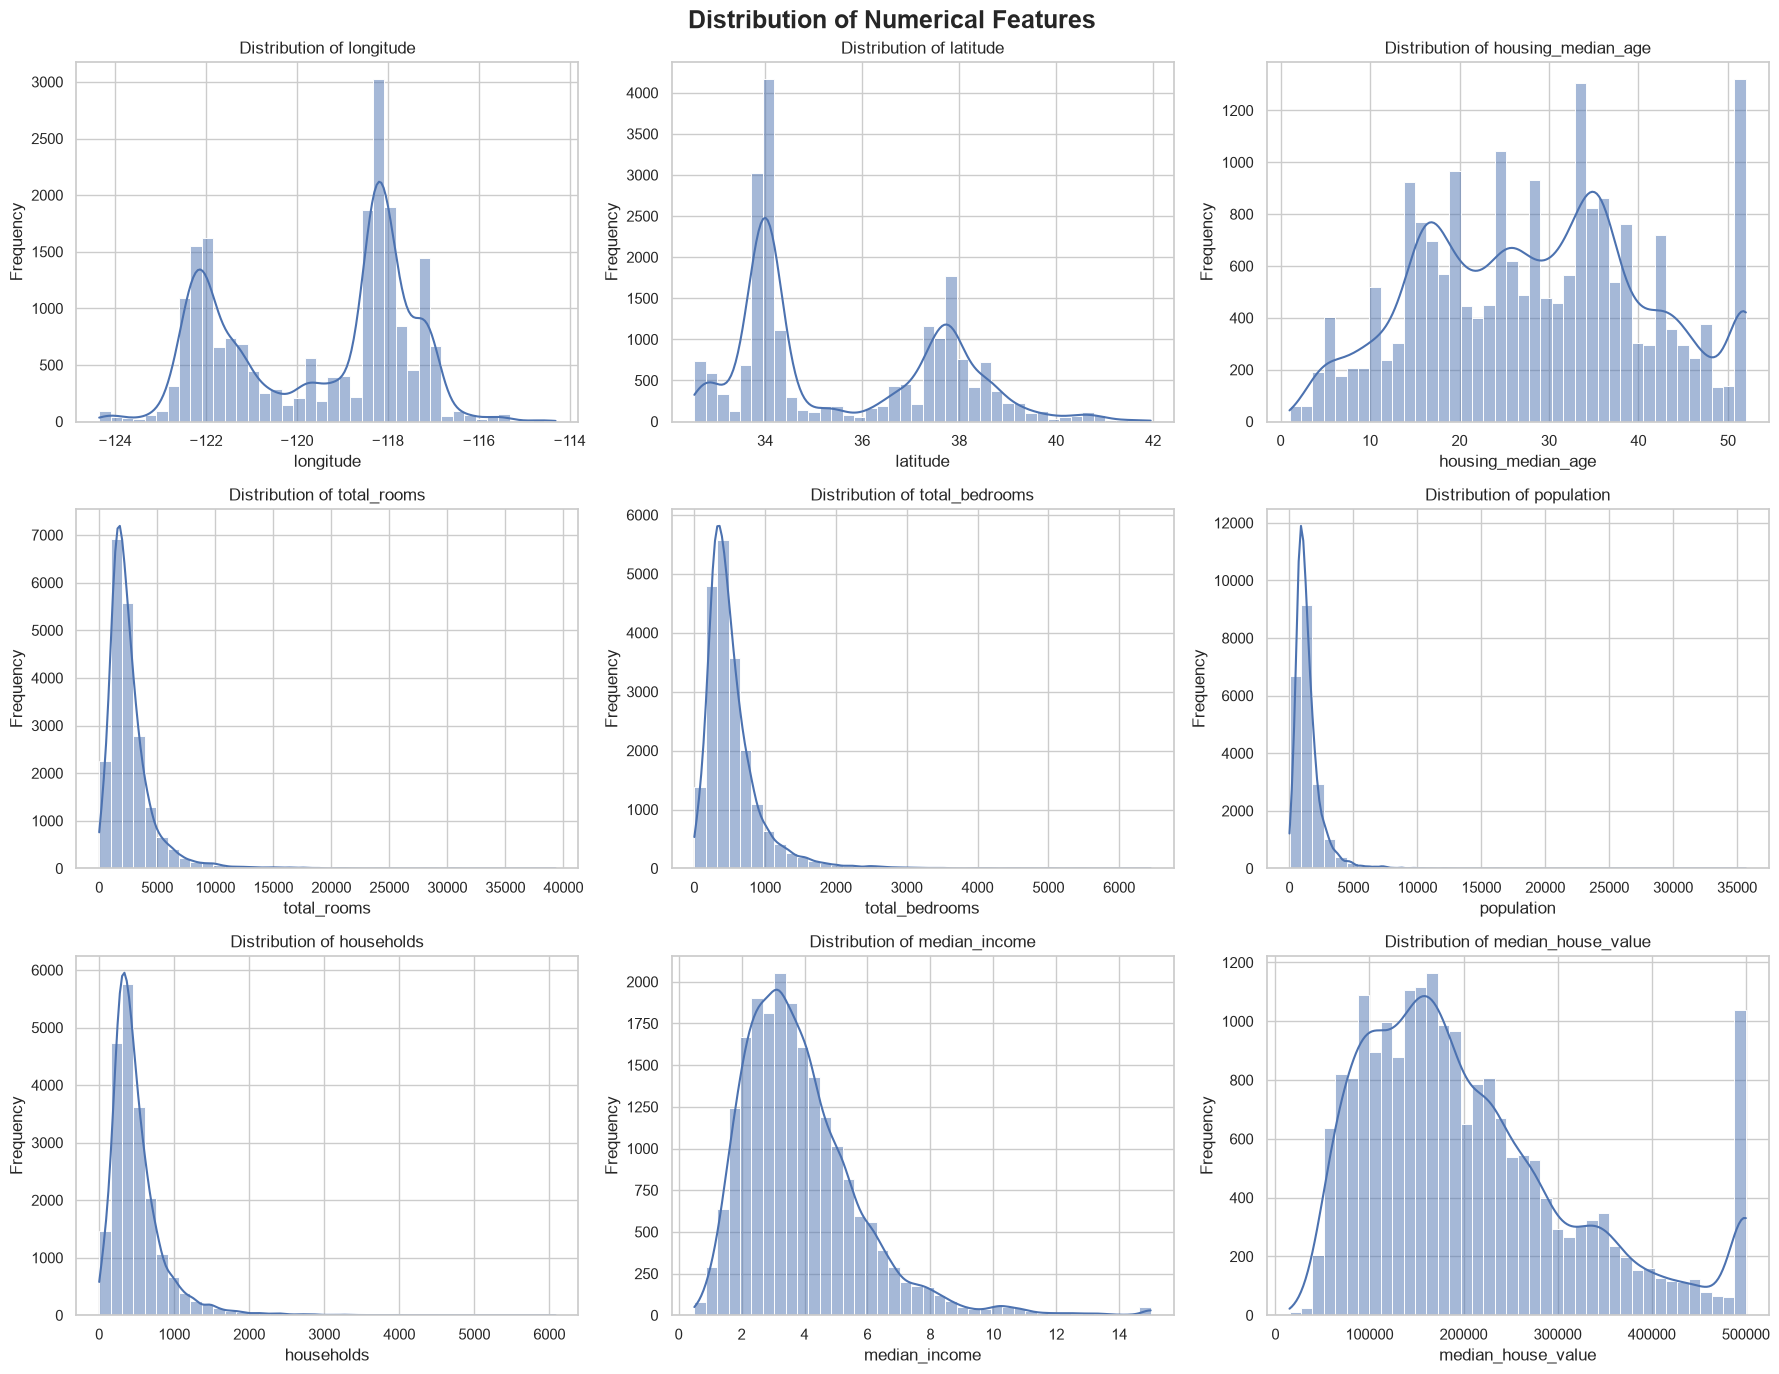

In [10]:

# ==========================================
# 3.1 DISTRIBUTION OF NUMERICAL FEATURES
# ==========================================

# Select numerical columns
numerical_columns = df.select_dtypes(include=np.number).columns

# Create a grid of histograms
fig, axes = plt.subplots(3, 3, figsize=(18, 14))

axes = axes.flatten()

for i, column in enumerate(numerical_columns):
    sns.histplot(
        data=df,
        x=column,
        bins=40,
        kde=True,
        ax=axes[i]
    )

    axes[i].set_title(f'Distribution of {column}')
    axes[i].set_xlabel(column)
    axes[i].set_ylabel('Frequency')

plt.suptitle(
    'Distribution of Numerical Features',
    fontsize=18,
    fontweight='bold'
)

plt.tight_layout()
plt.show()



### 3.2 Correlation Analysis

A correlation matrix is generated to measure the strength and direction of linear relationships between numerical variables.

A heatmap is used to visualize these correlations and identify features that may have a significant relationship with the target variable, median_house_value.

This analysis also provides an initial understanding of potential multicollinearity among independent variables.


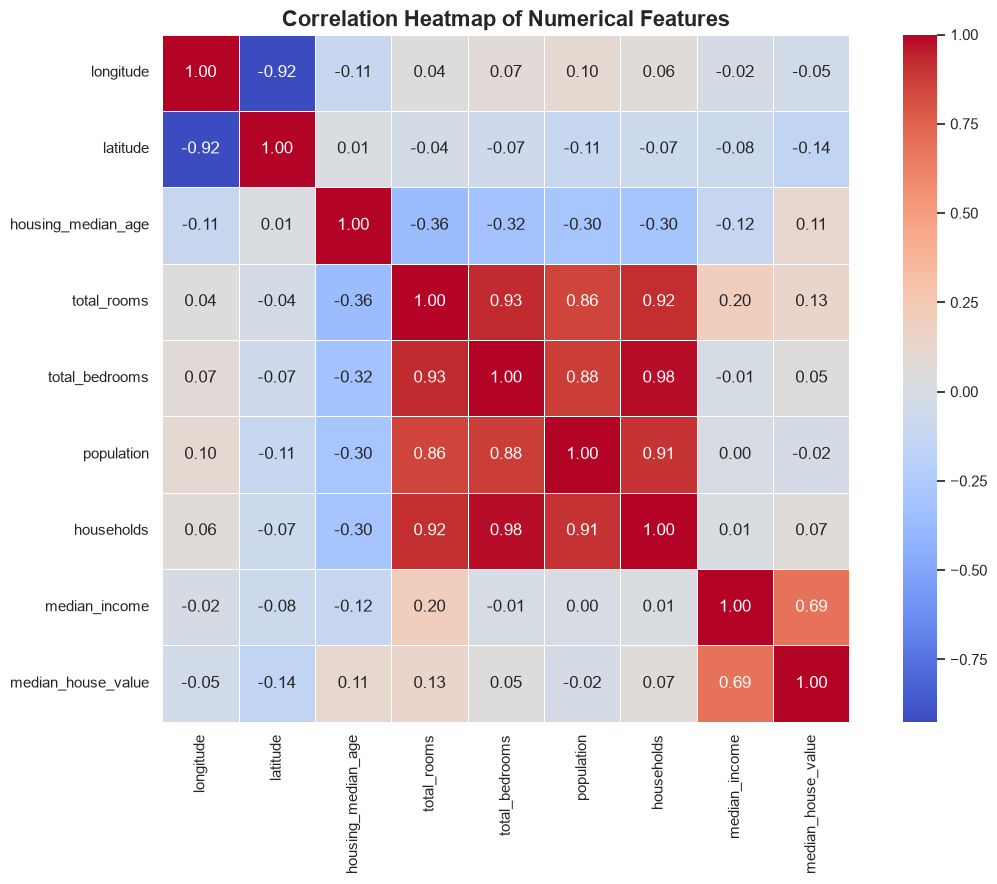

In [11]:

# ==========================================
# 3.2 CORRELATION HEATMAP
# ==========================================

# Calculate correlation matrix
correlation_matrix = df.select_dtypes(
    include=np.number
).corr()

# Plot correlation heatmap
plt.figure(figsize=(12, 9))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5,
    square=True
)

plt.title(
    'Correlation Heatmap of Numerical Features',
    fontsize=16,
    fontweight='bold'
)

plt.tight_layout()
plt.show()



### 3.3 Outlier Detection

Boxplots are used to examine the spread of numerical variables and identify potential outliers.

Observations beyond the whiskers may indicate unusually high or low values. These observations will be investigated rather than automatically removed, as they may represent genuine housing characteristics.


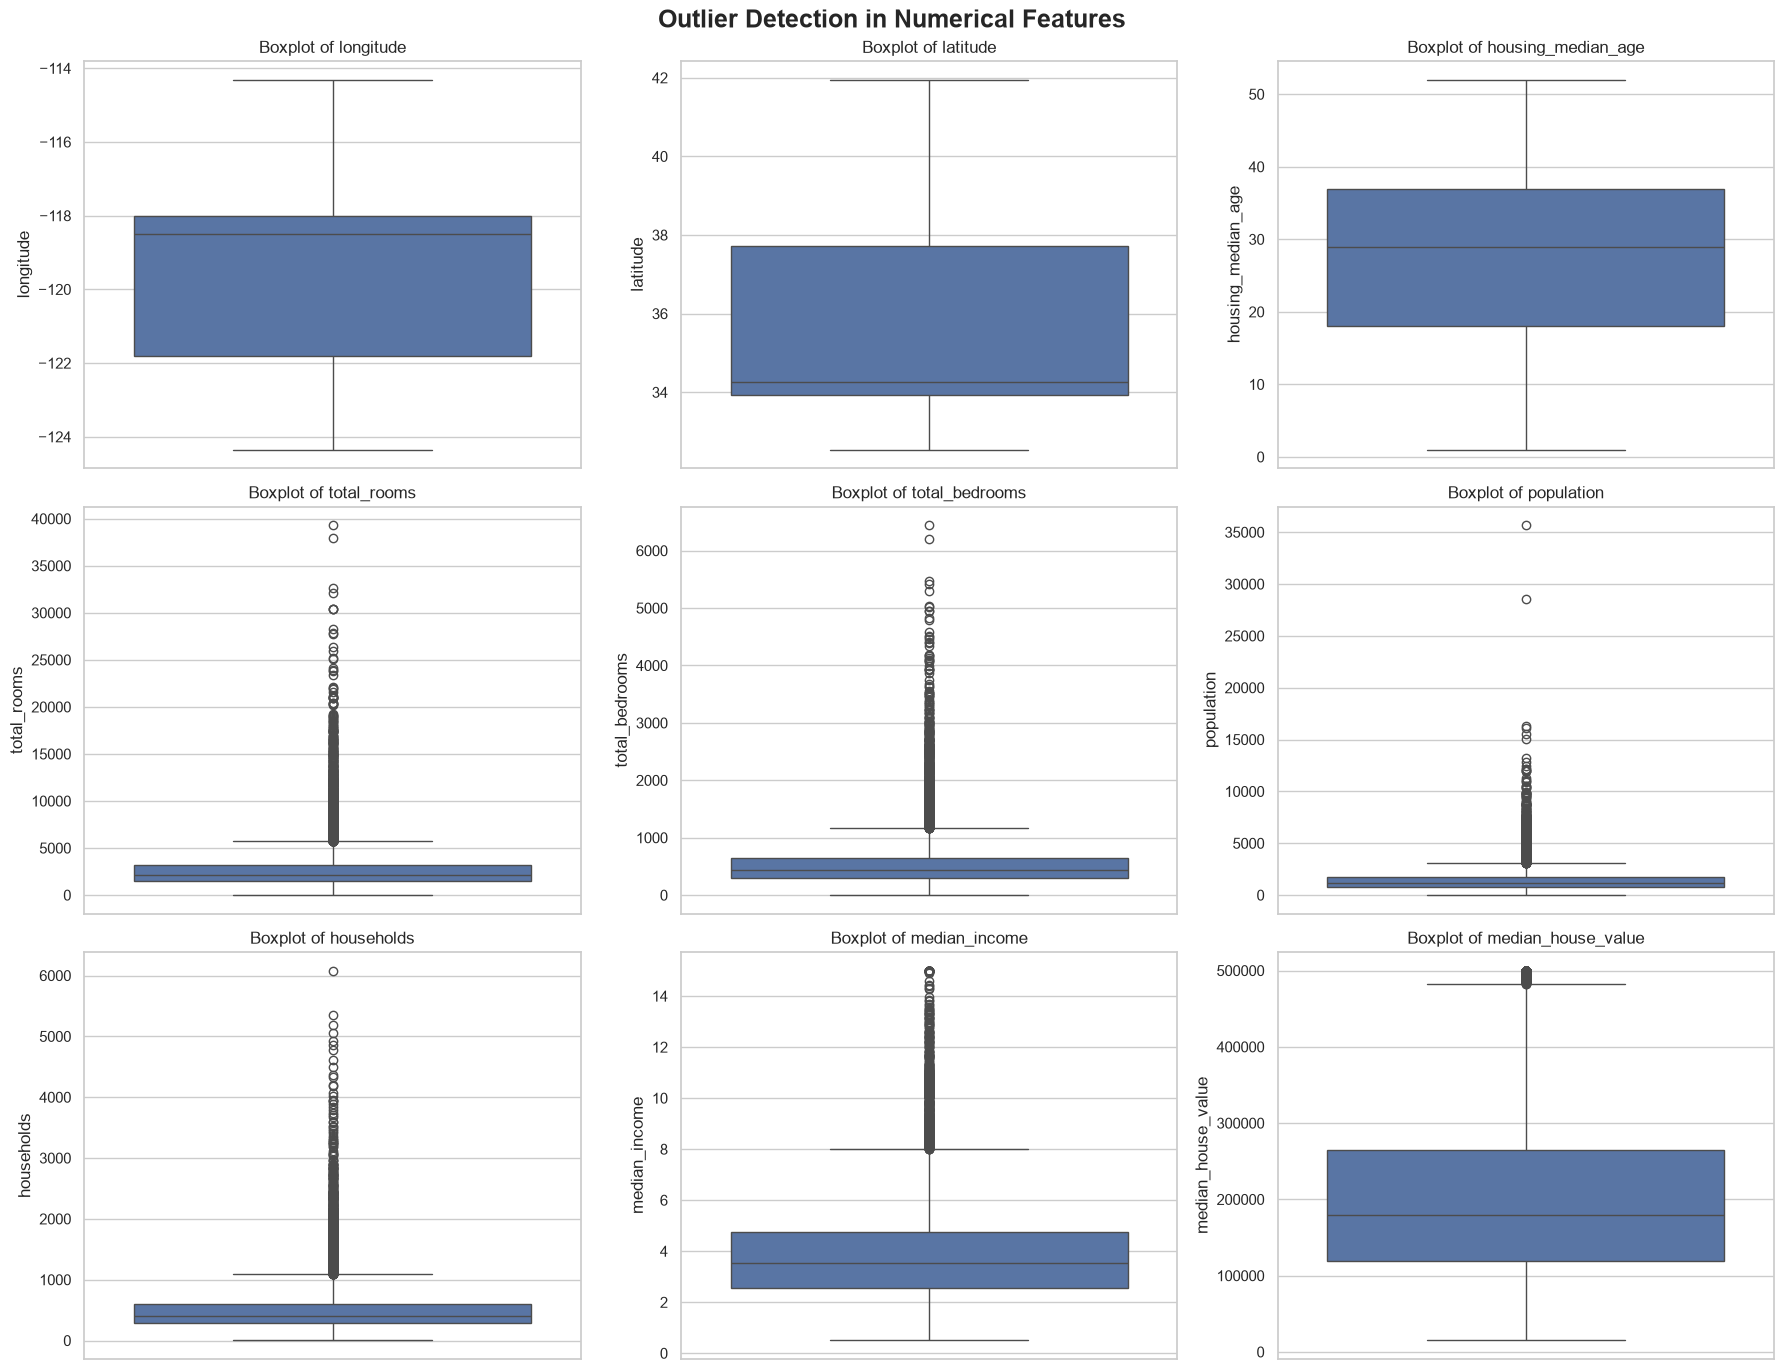

In [12]:

# ==========================================
# 3.3 OUTLIER DETECTION USING BOXPLOTS
# ==========================================

# Select numerical features
numerical_columns = df.select_dtypes(
    include=np.number
).columns

# Create boxplots
fig, axes = plt.subplots(3, 3, figsize=(18, 14))

axes = axes.flatten()

for i, column in enumerate(numerical_columns):
    sns.boxplot(
        data=df,
        y=column,
        ax=axes[i]
    )

    axes[i].set_title(f'Boxplot of {column}')
    axes[i].set_ylabel(column)

plt.suptitle(
    'Outlier Detection in Numerical Features',
    fontsize=18,
    fontweight='bold'
)

plt.tight_layout()
plt.show()



### 3.4 Geographical Distribution of Housing Prices

A geographical scatter plot is generated using longitude and latitude to visualize the spatial distribution of housing observations.

The color intensity represents median house values, allowing us to identify geographical patterns and regions with relatively higher or lower housing prices.


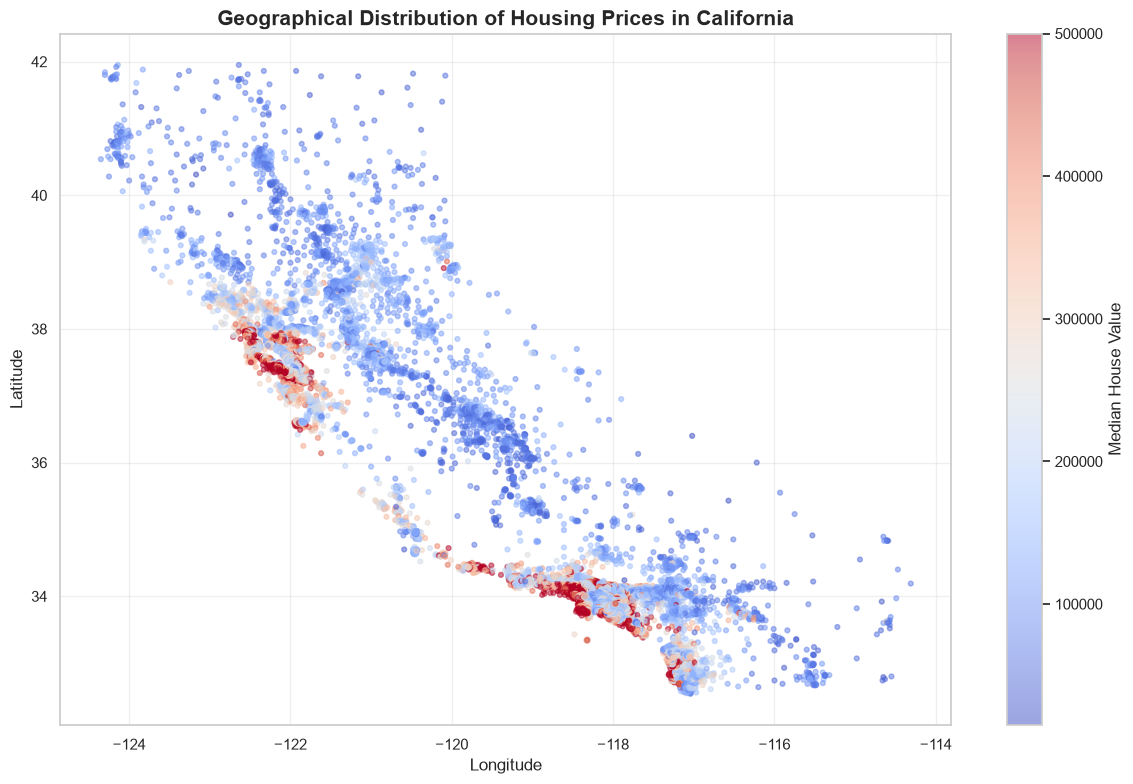

In [13]:

# ==========================================
# 3.4 GEOGRAPHICAL DISTRIBUTION
# ==========================================

plt.figure(figsize=(12, 8))

scatter = plt.scatter(
    df['longitude'],
    df['latitude'],
    c=df['median_house_value'],
    cmap='coolwarm',
    alpha=0.5,
    s=12
)

plt.colorbar(
    scatter,
    label='Median House Value'
)

plt.title(
    'Geographical Distribution of Housing Prices in California',
    fontsize=15,
    fontweight='bold'
)

plt.xlabel('Longitude')
plt.ylabel('Latitude')

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()



### 3.5 Housing Prices by Ocean Proximity

The relationship between ocean proximity and median house values is examined using boxplots.

This analysis helps determine whether geographical proximity to the ocean is associated with differences in housing prices across the five categorical groups.


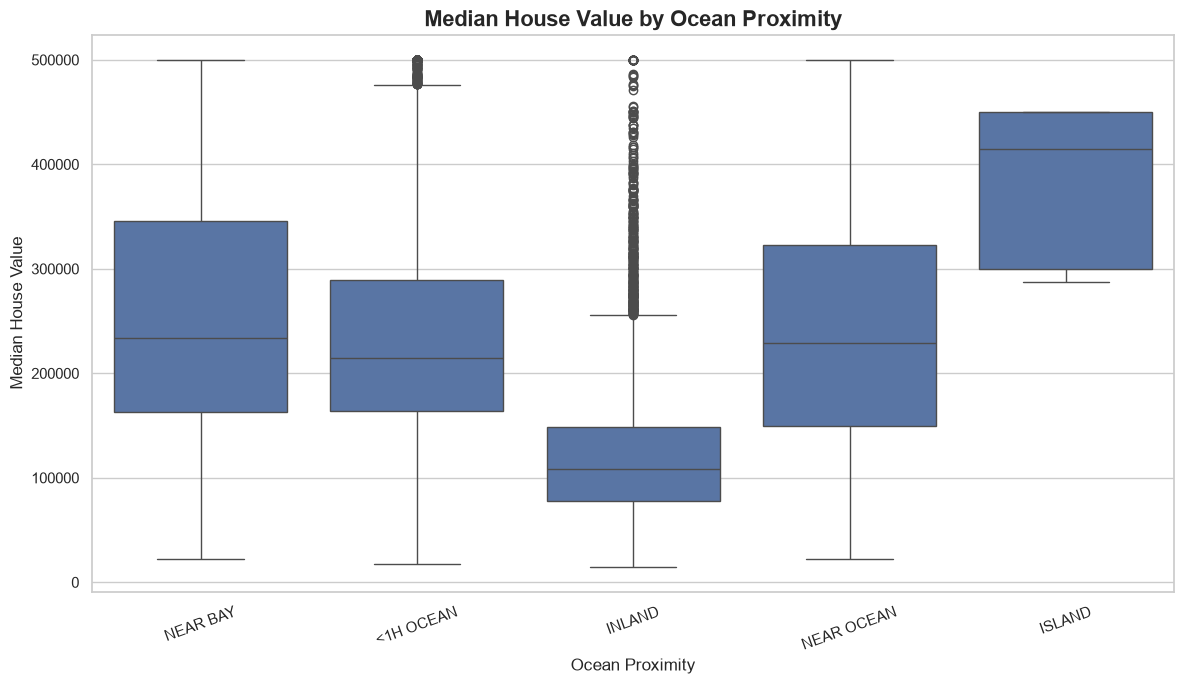

In [14]:

# ==========================================
# 3.5 HOUSING PRICES BY OCEAN PROXIMITY
# ==========================================

plt.figure(figsize=(12, 7))

sns.boxplot(
    data=df,
    x='ocean_proximity',
    y='median_house_value'
)

plt.title(
    'Median House Value by Ocean Proximity',
    fontsize=16,
    fontweight='bold'
)

plt.xlabel('Ocean Proximity')
plt.ylabel('Median House Value')

plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


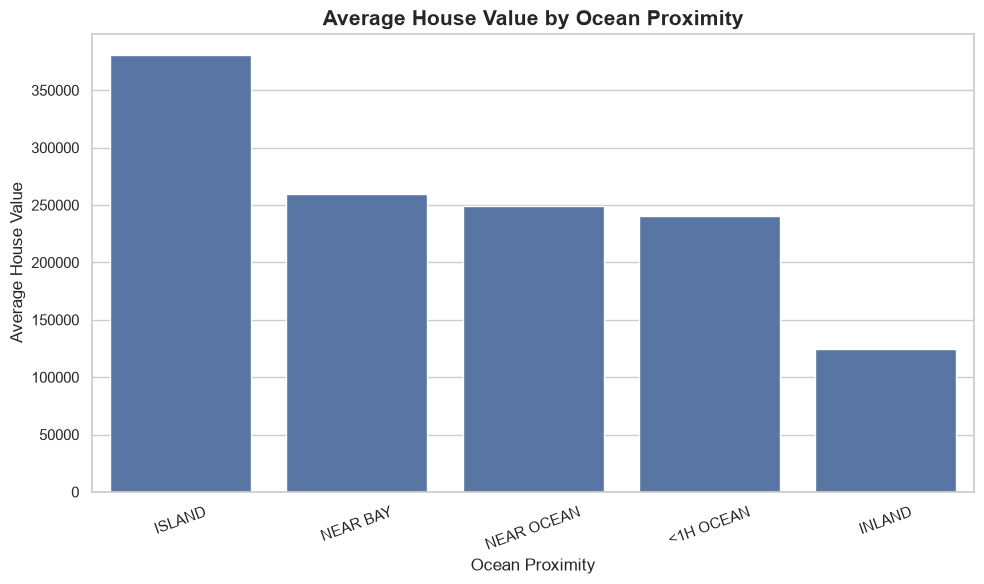

ocean_proximity
ISLAND       380440.000
NEAR BAY     259212.312
NEAR OCEAN   249433.977
<1H OCEAN    240084.285
INLAND       124805.392
Name: median_house_value, dtype: float64

In [15]:

# Calculate average house value by ocean proximity
ocean_price = df.groupby(
    'ocean_proximity'
)['median_house_value'].mean().sort_values(
    ascending=False
)

# Plot average house values
plt.figure(figsize=(10, 6))

sns.barplot(
    x=ocean_price.index,
    y=ocean_price.values
)

plt.title(
    'Average House Value by Ocean Proximity',
    fontsize=15,
    fontweight='bold'
)

plt.xlabel('Ocean Proximity')
plt.ylabel('Average House Value')

plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

# Display the corresponding values
ocean_price



### 3.6 Key Findings from Exploratory Data Analysis

The exploratory analysis provides the following insights:

1. **Feature Distributions:** Several numerical variables exhibit skewed distributions and varying ranges.

2. **Correlation Analysis:** Median income appears to be an important variable associated with median house values. Correlations among independent variables will also be investigated for potential multicollinearity.

3. **Outlier Detection:** Several numerical features contain potential extreme observations that require further consideration.

4. **Geographical Patterns:** Housing prices demonstrate geographical variation across California, suggesting that location-related features may contribute to prediction performance.

5. **Ocean Proximity:** Housing price distributions differ across ocean proximity categories, indicating that this categorical feature may contain useful predictive information.

These findings will guide the subsequent data preprocessing, feature engineering, and regression modeling stages.



## 4. Data Preprocessing

Data preprocessing involves preparing the dataset for regression modeling by separating the target variable, splitting the data, and handling missing values.

### 4.1 Separating Features and Target Variable

The independent variables are separated from the dependent variable.

The target variable for this project is `median_house_value`, while all remaining columns are considered independent features.


In [16]:

# ==========================================
# 4.1 SEPARATE FEATURES AND TARGET VARIABLE
# ==========================================

# Define independent features
X = df.drop(columns=['median_house_value'])

# Define dependent target variable
y = df['median_house_value']

print("Feature dataset shape:", X.shape)
print("Target dataset shape:", y.shape)

print("\nTarget variable:", y.name)


Feature dataset shape: (20640, 9)
Target dataset shape: (20640,)

Target variable: median_house_value



### 4.2 Train-Test Split

The dataset is divided into training and testing subsets using an 80:20 ratio.

The training dataset is used to develop the regression models, while the testing dataset is reserved for evaluating their performance on unseen observations.

A fixed random state is used to ensure reproducibility.


In [17]:

# ==========================================
# 4.2 TRAIN-TEST SPLIT
# ==========================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training features shape:", X_train.shape)
print("Testing features shape:", X_test.shape)

print("\nTraining target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)


Training features shape: (16512, 9)
Testing features shape: (4128, 9)

Training target shape: (16512,)
Testing target shape: (4128,)



### 4.3 Identifying Numerical and Categorical Features

The independent variables are categorized into numerical and categorical features.

Numerical variables will require missing value imputation and standardization, whereas categorical variables will require encoding before being used in regression models.


In [18]:

# ==========================================
# 4.3 IDENTIFY FEATURE TYPES
# ==========================================

# Identify numerical features
numerical_features = X_train.select_dtypes(
    include=np.number
).columns.tolist()

# Identify categorical features
categorical_features = X_train.select_dtypes(
    exclude=np.number
).columns.tolist()

print("Numerical Features:")
print(numerical_features)

print("\nCategorical Features:")
print(categorical_features)

print("\nNumber of numerical features:", len(numerical_features))
print("Number of categorical features:", len(categorical_features))


Numerical Features:
['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income']

Categorical Features:
['ocean_proximity']

Number of numerical features: 8
Number of categorical features: 1



### 4.4 Missing Value Treatment

The dataset contains 207 missing values in the `total_bedrooms` feature.

To handle these missing observations, median imputation is applied using Scikit-learn's SimpleImputer.

The imputer is fitted only on the training data. The same learned median values are then used to transform the testing data, preventing information leakage.


In [19]:

# ==========================================
# 4.4 MEDIAN IMPUTATION
# ==========================================

# Initialize median imputer
median_imputer = SimpleImputer(strategy='median')

# Fit imputer on training data and transform it
X_train[numerical_features] = median_imputer.fit_transform(
    X_train[numerical_features]
)

# Transform testing data using training medians
X_test[numerical_features] = median_imputer.transform(
    X_test[numerical_features]
)

print("Missing values handled successfully!")


Missing values handled successfully!



### 4.5 Verification of Missing Value Treatment

After applying median imputation, the training and testing datasets are examined to confirm that no missing values remain in the numerical features.


In [20]:

# ==========================================
# 4.5 VERIFY MISSING VALUES
# ==========================================

print("Missing values in training features:")
print(X_train.isnull().sum())

print("\nMissing values in testing features:")
print(X_test.isnull().sum())

print("\nTotal missing values in training data:",
      X_train.isnull().sum().sum())

print("Total missing values in testing data:",
      X_test.isnull().sum().sum())


Missing values in training features:
longitude             0
latitude              0
housing_median_age    0
total_rooms           0
total_bedrooms        0
population            0
households            0
median_income         0
ocean_proximity       0
dtype: int64

Missing values in testing features:
longitude             0
latitude              0
housing_median_age    0
total_rooms           0
total_bedrooms        0
population            0
households            0
median_income         0
ocean_proximity       0
dtype: int64

Total missing values in training data: 0
Total missing values in testing data: 0



### 4.6 Final Preprocessing Summary

The initial preprocessing stage has been completed successfully.

The dataset has been divided into training and testing subsets, and missing numerical values have been handled using median imputation.

The original categorical feature has been retained for subsequent encoding.

Feature engineering, categorical encoding, and standardization will be performed in the following stages.


In [21]:

# ==========================================
# 4.6 FINAL PREPROCESSING SUMMARY
# ==========================================

print("Training Dataset Shape:", X_train.shape)
print("Testing Dataset Shape:", X_test.shape)

print("\nTraining Target Shape:", y_train.shape)
print("Testing Target Shape:", y_test.shape)

print("\nTraining Dataset Preview:")
display(X_train.head())

print("\nTesting Dataset Preview:")
display(X_test.head())


Training Dataset Shape: (16512, 9)
Testing Dataset Shape: (4128, 9)

Training Target Shape: (16512,)
Testing Target Shape: (4128,)

Training Dataset Preview:


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,ocean_proximity
14196,-117.030,32.710,33.000,3126.000,627.000,2300.000,623.000,3.260,NEAR OCEAN
8267,-118.160,33.770,49.000,3382.000,787.000,1314.000,756.000,3.812,NEAR OCEAN
17445,-120.480,34.660,4.000,1897.000,331.000,915.000,336.000,4.156,NEAR OCEAN
14265,-117.110,32.690,36.000,1421.000,367.000,1418.000,355.000,1.942,NEAR OCEAN
2271,-119.800,36.780,43.000,2382.000,431.000,874.000,380.000,3.554,INLAND



Testing Dataset Preview:


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,ocean_proximity
20046,-119.010,36.060,25.000,1505.000,437.000,1392.000,359.000,1.681,INLAND
3024,-119.460,35.140,30.000,2943.000,437.000,1565.000,584.000,2.531,INLAND
15663,-122.440,37.800,52.000,3830.000,437.000,1310.000,963.000,3.480,NEAR BAY
20484,-118.720,34.280,17.000,3051.000,437.000,1705.000,495.000,5.738,<1H OCEAN
9814,-121.930,36.620,34.000,2351.000,437.000,1063.000,428.000,3.725,NEAR OCEAN



## 5. Feature Engineering and Multicollinearity Analysis

Feature engineering involves creating new variables from existing features to capture meaningful relationships and improve the predictive information available to regression models.

Multicollinearity analysis is also performed to identify highly correlated independent variables that may affect regression coefficient estimates.

### 5.1 Creating Ratio-Based Features

Three new features are created:

1. rooms_per_household: Average number of rooms per household.
2. bedrooms_per_room: Proportion of bedrooms relative to total rooms.
3. population_per_household: Average population per household.

These features provide additional insights into housing characteristics and household composition.


In [22]:

# ==========================================
# 5.1 CREATE RATIO-BASED FEATURES
# ==========================================

def create_ratio_features(data):
    data = data.copy()

    data['rooms_per_household'] = (
        data['total_rooms'] / data['households']
    )

    data['bedrooms_per_room'] = (
        data['total_bedrooms'] / data['total_rooms']
    )

    data['population_per_household'] = (
        data['population'] / data['households']
    )

    return data


# Apply feature engineering separately
X_train = create_ratio_features(X_train)
X_test = create_ratio_features(X_test)

print("Ratio-based features created successfully!")

print("\nTraining dataset shape:", X_train.shape)
print("Testing dataset shape:", X_test.shape)

print("\nNew features:")
print([
    'rooms_per_household',
    'bedrooms_per_room',
    'population_per_household'
])

display(X_train.head())


Ratio-based features created successfully!

Training dataset shape: (16512, 12)
Testing dataset shape: (4128, 12)

New features:
['rooms_per_household', 'bedrooms_per_room', 'population_per_household']


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,ocean_proximity,rooms_per_household,bedrooms_per_room,population_per_household
14196,-117.030,32.710,33.000,3126.000,627.000,2300.000,623.000,3.260,NEAR OCEAN,5.018,0.201,3.692
8267,-118.160,33.770,49.000,3382.000,787.000,1314.000,756.000,3.812,NEAR OCEAN,4.474,0.233,1.738
17445,-120.480,34.660,4.000,1897.000,331.000,915.000,336.000,4.156,NEAR OCEAN,5.646,0.174,2.723
14265,-117.110,32.690,36.000,1421.000,367.000,1418.000,355.000,1.942,NEAR OCEAN,4.003,0.258,3.994
2271,-119.800,36.780,43.000,2382.000,431.000,874.000,380.000,3.554,INLAND,6.268,0.181,2.300



### 5.2 Creating Interaction Features

An interaction feature is created by multiplying two existing independent variables.

The income_x_house_age feature combines median income and housing median age to capture a potential joint relationship between household income levels and housing age.

This feature will be evaluated during subsequent regression modeling.


In [23]:

# ==========================================
# 5.2 CREATE INTERACTION FEATURE
# ==========================================

def create_interaction_features(data):
    data = data.copy()

    data['income_x_house_age'] = (
        data['median_income'] *
        data['housing_median_age']
    )

    return data


# Apply interaction feature engineering
X_train = create_interaction_features(X_train)
X_test = create_interaction_features(X_test)

print("Interaction feature created successfully!")

print("\nTraining dataset shape:", X_train.shape)
print("Testing dataset shape:", X_test.shape)

display(
    X_train[
        ['median_income',
         'housing_median_age',
         'income_x_house_age']
    ].head()
)


Interaction feature created successfully!

Training dataset shape: (16512, 13)
Testing dataset shape: (4128, 13)


,median_income,housing_median_age,income_x_house_age
14196,3.260,33.000,107.567
8267,3.812,49.000,186.812
17445,4.156,4.000,16.625
14265,1.942,36.000,69.930
2271,3.554,43.000,152.831



### 5.3 Correlation Analysis of Engineered Features

A correlation heatmap is generated to examine the relationships between original numerical variables and newly engineered features.

This helps identify strong linear associations and provides an initial indication of potential multicollinearity.


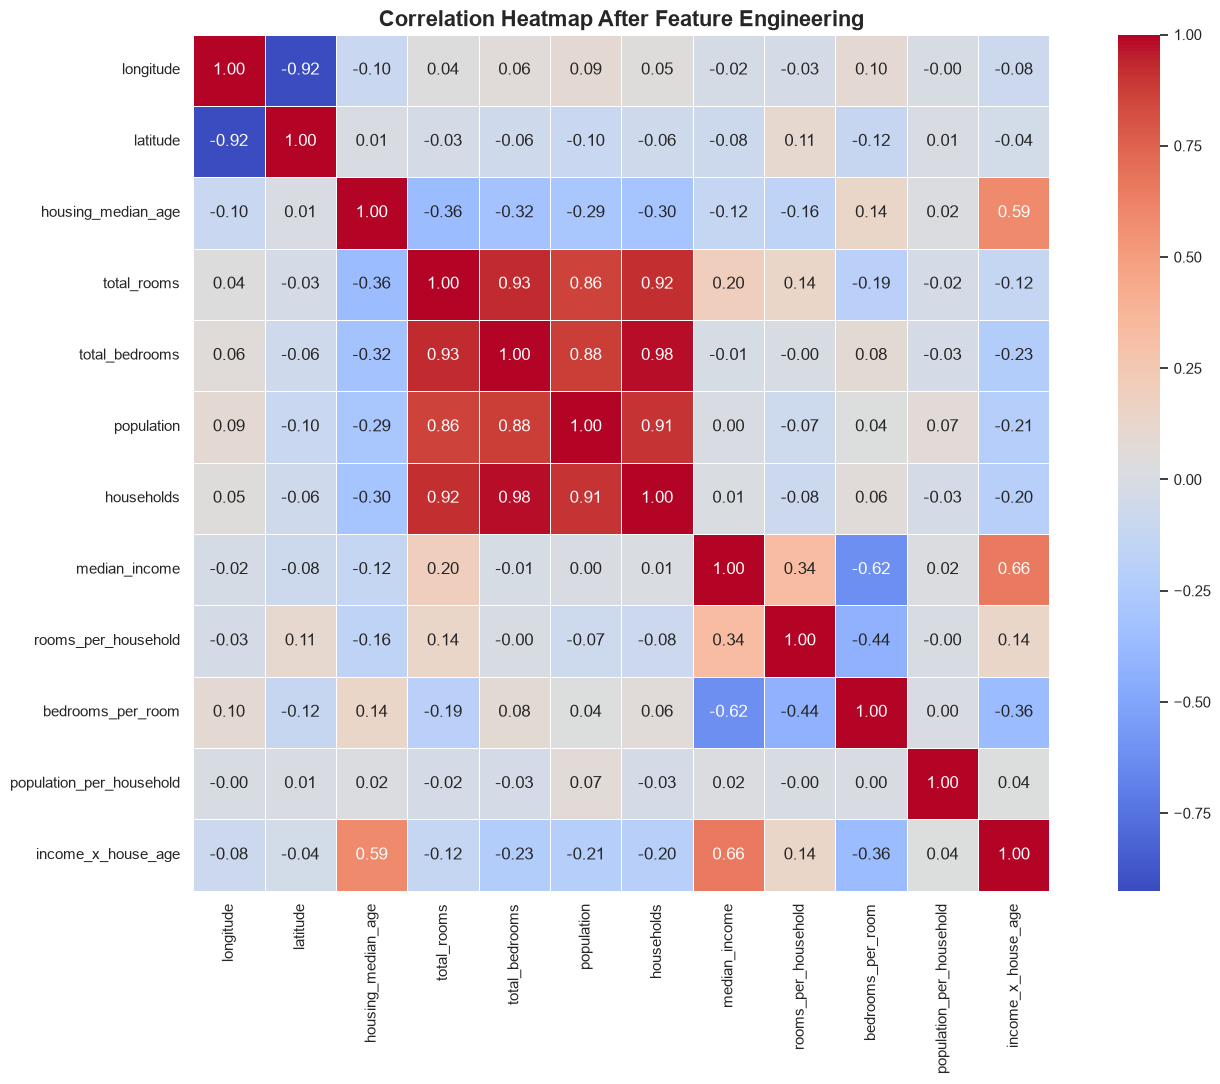

In [24]:
# ==========================================
# 5.3 CORRELATION HEATMAP
# ==========================================

# Select all numerical features from training data
engineered_numerical = X_train.select_dtypes(
    include=np.number
)

# Calculate correlation matrix
engineered_correlation = engineered_numerical.corr()

# Plot heatmap
plt.figure(figsize=(15, 11))

sns.heatmap(
    engineered_correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5,
    square=True
)

plt.title(
    'Correlation Heatmap After Feature Engineering',
    fontsize=16,
    fontweight='bold'
)

plt.tight_layout()
plt.show()


### 5.4 Variance Inflation Factor (VIF) Analysis

Variance Inflation Factor (VIF) is calculated to quantify multicollinearity among numerical independent variables.

Higher VIF values indicate that a feature can be explained by a linear combination of other independent variables.

The analysis helps identify variables that may cause unstable regression coefficient estimates, particularly in Ordinary Least Squares regression.


In [25]:
%pip install statsmodels

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [25]:
# ==========================================
# 5.4 VARIANCE INFLATION FACTOR (VIF)
# ==========================================

from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

# Select numerical independent features
vif_features = X_train.select_dtypes(
    include=np.number
).copy()

# Add constant for VIF calculation
vif_data = add_constant(vif_features)

# Calculate VIF
vif_results = pd.DataFrame()

vif_results['Feature'] = vif_features.columns

vif_results['VIF'] = [
    variance_inflation_factor(
        vif_data.values,
        i + 1
    )
    for i in range(len(vif_features.columns))
]

# Sort by VIF in descending order
vif_results = vif_results.sort_values(
    by='VIF',
    ascending=False
)

print("Variance Inflation Factor (VIF) Results:")
display(vif_results)


Variance Inflation Factor (VIF) Results:


,Feature,VIF
4,total_bedrooms,50.698
6,households,46.004
3,total_rooms,19.550
1,latitude,9.418
0,longitude,9.091
11,income_x_house_age,9.088
7,median_income,7.590
5,population,6.817
2,housing_median_age,5.444
9,bedrooms_per_room,2.807


### 5.5 Visualization of VIF Values

A bar chart is generated to compare VIF values across numerical independent variables.

This visualization helps identify features with relatively higher multicollinearity and provides a clearer understanding of the overall correlation structure.


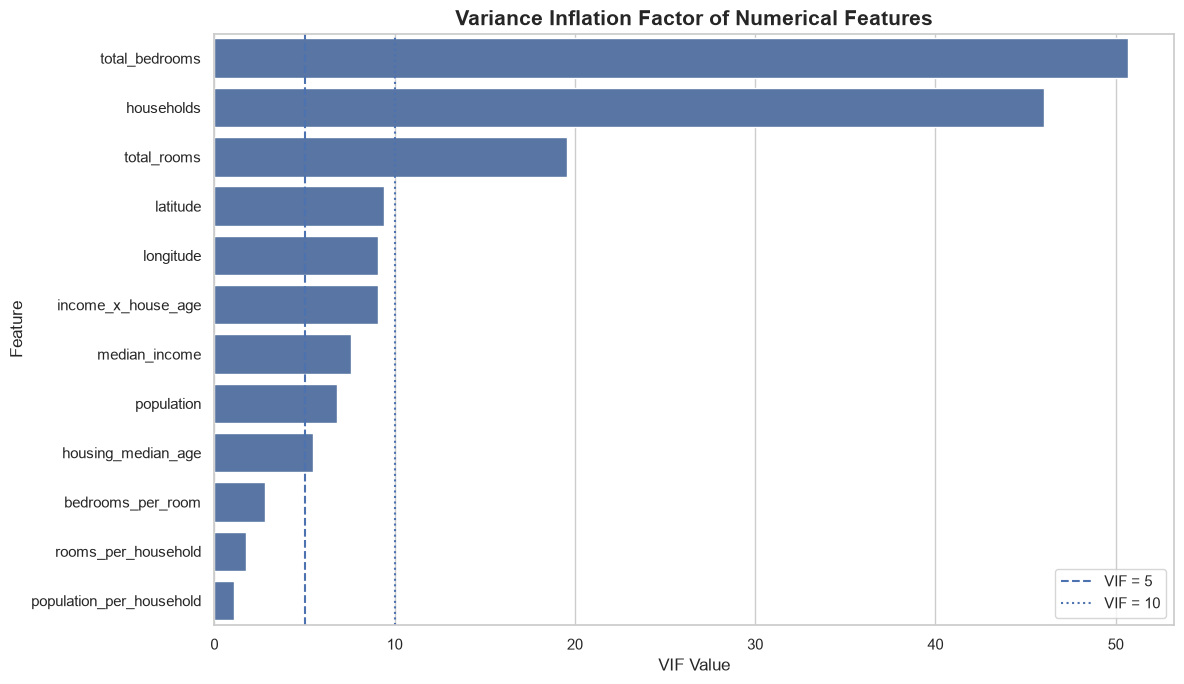

In [26]:
# ==========================================
# 5.5 VIF VISUALIZATION
# ==========================================

plt.figure(figsize=(12, 7))

sns.barplot(
    data=vif_results,
    x='VIF',
    y='Feature'
)

# Reference threshold
plt.axvline(
    x=5,
    linestyle='--',
    label='VIF = 5'
)

plt.axvline(
    x=10,
    linestyle=':',
    label='VIF = 10'
)

plt.title(
    'Variance Inflation Factor of Numerical Features',
    fontsize=15,
    fontweight='bold'
)

plt.xlabel('VIF Value')
plt.ylabel('Feature')

plt.legend()
plt.tight_layout()
plt.show()


### 5.6 Final Feature Engineering Summary

Feature engineering has been completed by creating three ratio-based features and one interaction feature.

Correlation analysis and Variance Inflation Factor analysis have also been performed to investigate relationships and potential multicollinearity among numerical independent variables.

The resulting dataset will be used in the subsequent preprocessing and regression modeling stages.


In [27]:
# ==========================================
# 5.6 FINAL FEATURE ENGINEERING SUMMARY
# ==========================================

print("FINAL FEATURE ENGINEERING SUMMARY")
print("=" * 45)

print("\nTraining dataset shape:", X_train.shape)
print("Testing dataset shape:", X_test.shape)

print("\nTotal independent features:", X_train.shape[1])

print("\nEngineered Features:")
engineered_features = [
    'rooms_per_household',
    'bedrooms_per_room',
    'population_per_household',
    'income_x_house_age'
]

for feature in engineered_features:
    print("-", feature)

print("\nMissing values in training data:",
      X_train.isnull().sum().sum())

print("Missing values in testing data:",
      X_test.isnull().sum().sum())

print("\nInfinite values in training data:",
      np.isinf(X_train.select_dtypes(include=np.number)).sum().sum())

print("\nInfinite values in testing data:",
      np.isinf(X_test.select_dtypes(include=np.number)).sum().sum())

print("\nFeature engineering completed successfully!")


FINAL FEATURE ENGINEERING SUMMARY

Training dataset shape: (16512, 13)
Testing dataset shape: (4128, 13)

Total independent features: 13

Engineered Features:
- rooms_per_household
- bedrooms_per_room
- population_per_household
- income_x_house_age

Missing values in training data: 0
Missing values in testing data: 0

Infinite values in training data: 0

Infinite values in testing data: 0

Feature engineering completed successfully!


### 5.7 Interpretation of Feature Engineering and Multicollinearity Analysis

Feature engineering successfully introduced three ratio-based features and one interaction feature, increasing the number of independent variables from 9 to 13.

The correlation heatmap revealed strong relationships among several original numerical variables, particularly total_rooms, total_bedrooms, and households.

Variance Inflation Factor (VIF) analysis identified significant multicollinearity in total_bedrooms (50.698), households (46.004), and total_rooms (19.550).

The engineered ratio features demonstrated relatively low VIF values, indicating lower multicollinearity compared to several original variables.

The interaction feature income_x_house_age recorded a VIF of 9.088.

The identified features have been retained for subsequent regression modeling to evaluate the effectiveness of Ridge and Lasso regularization in handling multicollinearity.

All engineered datasets were verified to contain zero missing and infinite values.



## 6. Feature Scaling and Encoding

Feature scaling and categorical encoding are essential preprocessing steps for regression modeling.

Numerical features are standardized using StandardScaler, while categorical features are transformed using OneHotEncoder.

A ColumnTransformer is used to combine both transformations into a single preprocessing pipeline.

All transformations are fitted exclusively on the training dataset to prevent data leakage.


In [28]:
# ==========================================
# 6.1 IDENTIFY NUMERICAL AND CATEGORICAL FEATURES
# ==========================================

# Identify numerical features
numerical_features = X_train.select_dtypes(
    include=np.number
).columns.tolist()

# Identify categorical features
categorical_features = X_train.select_dtypes(
    exclude=np.number
).columns.tolist()

print("Numerical Features:")
print(numerical_features)

print("\nCategorical Features:")
print(categorical_features)

print("\nNumber of numerical features:",
      len(numerical_features))

print("Number of categorical features:",
      len(categorical_features))

print("\nTotal features:",
      len(numerical_features) + len(categorical_features))


Numerical Features:
['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'rooms_per_household', 'bedrooms_per_room', 'population_per_household', 'income_x_house_age']

Categorical Features:
['ocean_proximity']

Number of numerical features: 12
Number of categorical features: 1

Total features: 13


### 6.2 Numerical Feature Standardization

StandardScaler is used to standardize numerical independent variables.

The transformation centers each feature around zero and scales it according to its standard deviation.

This ensures that features with larger numerical ranges do not disproportionately influence the regularization penalties used by Ridge and Lasso regression.


In [29]:
# ==========================================
# 6.2 STANDARDIZE NUMERICAL FEATURES
# ==========================================

from sklearn.preprocessing import StandardScaler

# Initialize StandardScaler
numerical_scaler = StandardScaler()

# Fit on training data and transform
X_train_numerical_scaled = numerical_scaler.fit_transform(
    X_train[numerical_features]
)

# Transform testing data using training statistics
X_test_numerical_scaled = numerical_scaler.transform(
    X_test[numerical_features]
)

print("Numerical feature scaling completed successfully!")

print("\nTraining numerical data shape:",
      X_train_numerical_scaled.shape)

print("Testing numerical data shape:",
      X_test_numerical_scaled.shape)

# Verify standardization
print("\nMean of first five scaled features:")
print(X_train_numerical_scaled.mean(axis=0)[:5])

print("\nStandard deviation of first five scaled features:")
print(X_train_numerical_scaled.std(axis=0)[:5])


Numerical feature scaling completed successfully!

Training numerical data shape: (16512, 12)
Testing numerical data shape: (4128, 12)

Mean of first five scaled features:
[ 1.77678716e-15  3.38574991e-15 -1.67824411e-17  3.52861581e-17
 -4.47531762e-17]

Standard deviation of first five scaled features:
[1. 1. 1. 1. 1.]


### 6.3 Categorical Feature Encoding

OneHotEncoder is used to convert the ocean_proximity categorical variable into numerical binary columns.

Each category receives a separate encoded feature.

The handle_unknown='ignore' parameter ensures that previously unseen categories in the testing dataset do not cause preprocessing errors.


In [30]:
# ==========================================
# 6.3 ENCODE CATEGORICAL FEATURES
# ==========================================

from sklearn.preprocessing import OneHotEncoder

# Initialize OneHotEncoder
categorical_encoder = OneHotEncoder(
    handle_unknown='ignore'
)

# Fit on training data and transform
X_train_categorical_encoded = categorical_encoder.fit_transform(
    X_train[categorical_features]
)

# Transform testing data
X_test_categorical_encoded = categorical_encoder.transform(
    X_test[categorical_features]
)

print("Categorical encoding completed successfully!")

print("\nTraining categorical data shape:",
      X_train_categorical_encoded.shape)

print("Testing categorical data shape:",
      X_test_categorical_encoded.shape)

print("\nEncoded categories:")
print(categorical_encoder.categories_)


Categorical encoding completed successfully!

Training categorical data shape: (16512, 5)
Testing categorical data shape: (4128, 5)

Encoded categories:
[array(['<1H OCEAN', 'INLAND', 'ISLAND', 'NEAR BAY', 'NEAR OCEAN'],
      dtype=object)]


### 6.4 Combining Transformations Using ColumnTransformer

ColumnTransformer is used to apply different preprocessing operations to different groups of features.

StandardScaler is applied to numerical features, while OneHotEncoder is applied to categorical features.

Combining these operations into a single transformer ensures consistent preprocessing and simplifies integration with regression models.


In [31]:
# ==========================================
# 6.4 CREATE COLUMN TRANSFORMER
# ==========================================

from sklearn.compose import ColumnTransformer

# Combine numerical and categorical transformations
preprocessor = ColumnTransformer(
    transformers=[
        (
            'num',
            StandardScaler(),
            numerical_features
        ),
        (
            'cat',
            OneHotEncoder(handle_unknown='ignore'),
            categorical_features
        )
    ]
)

print("ColumnTransformer created successfully!")

print("\nNumerical transformation: StandardScaler")
print("Categorical transformation: OneHotEncoder")
print("\nPreprocessing configuration:")
print(preprocessor)


ColumnTransformer created successfully!

Numerical transformation: StandardScaler
Categorical transformation: OneHotEncoder

Preprocessing configuration:
ColumnTransformer(transformers=[('num', StandardScaler(),
                                 ['longitude', 'latitude', 'housing_median_age',
                                  'total_rooms', 'total_bedrooms', 'population',
                                  'households', 'median_income',
                                  'rooms_per_household', 'bedrooms_per_room',
                                  'population_per_household',
                                  'income_x_house_age']),
                                ('cat', OneHotEncoder(handle_unknown='ignore'),
                                 ['ocean_proximity'])])


### 6.5 Applying the Preprocessing Pipeline

The combined ColumnTransformer is fitted on the training dataset and used to transform both training and testing datasets.

The training dataset is processed using fit_transform(), while the testing dataset is processed using transform().

This ensures that the testing dataset remains independent of the preprocessing parameter estimation process.


In [32]:
# ==========================================
# 6.5 APPLY PREPROCESSING TRANSFORMATIONS
# ==========================================

# Fit and transform training dataset
X_train_processed = preprocessor.fit_transform(X_train)

# Transform testing dataset
X_test_processed = preprocessor.transform(X_test)

# Get transformed feature names
processed_feature_names = preprocessor.get_feature_names_out()

print("Preprocessing applied successfully!")

print("\nProcessed Training Dataset Shape:",
      X_train_processed.shape)

print("Processed Testing Dataset Shape:",
      X_test_processed.shape)

print("\nTotal transformed features:",
      len(processed_feature_names))

print("\nTransformed Feature Names:")
print(processed_feature_names)


Preprocessing applied successfully!

Processed Training Dataset Shape: (16512, 17)
Processed Testing Dataset Shape: (4128, 17)

Total transformed features: 17

Transformed Feature Names:
['num__longitude' 'num__latitude' 'num__housing_median_age'
 'num__total_rooms' 'num__total_bedrooms' 'num__population'
 'num__households' 'num__median_income' 'num__rooms_per_household'
 'num__bedrooms_per_room' 'num__population_per_household'
 'num__income_x_house_age' 'cat__ocean_proximity_<1H OCEAN'
 'cat__ocean_proximity_INLAND' 'cat__ocean_proximity_ISLAND'
 'cat__ocean_proximity_NEAR BAY' 'cat__ocean_proximity_NEAR OCEAN']


### 6.6 Inspecting the Processed Dataset

The transformed training dataset is converted into a Pandas DataFrame using the generated feature names.

The final dataset is inspected to verify the preprocessing results and ensure that the transformed features are suitable for subsequent regression modeling.


In [33]:
# ==========================================
# 6.6 DISPLAY PROCESSED DATASET
# ==========================================

from scipy.sparse import issparse

# Convert training data into DataFrame
if issparse(X_train_processed):
    X_train_processed_df = pd.DataFrame.sparse.from_spmatrix(
        X_train_processed,
        columns=processed_feature_names,
        index=X_train.index
    )
else:
    X_train_processed_df = pd.DataFrame(
        X_train_processed,
        columns=processed_feature_names,
        index=X_train.index
    )

# Convert testing data into DataFrame
if issparse(X_test_processed):
    X_test_processed_df = pd.DataFrame.sparse.from_spmatrix(
        X_test_processed,
        columns=processed_feature_names,
        index=X_test.index
    )
else:
    X_test_processed_df = pd.DataFrame(
        X_test_processed,
        columns=processed_feature_names,
        index=X_test.index
    )

print("Processed Training Dataset Preview:")
display(X_train_processed_df.head())

print("\nProcessed Testing Dataset Preview:")
display(X_test_processed_df.head())


Processed Training Dataset Preview:


,num__longitude,num__latitude,num__housing_median_age,num__total_rooms,num__total_bedrooms,num__population,num__households,num__median_income,num__rooms_per_household,num__bedrooms_per_room,num__population_per_household,num__income_x_house_age,cat__ocean_proximity_<1H OCEAN,cat__ocean_proximity_INLAND,cat__ocean_proximity_ISLAND,cat__ocean_proximity_NEAR BAY,cat__ocean_proximity_NEAR OCEAN
14196,1.273,-1.373,0.348,0.223,0.211,0.768,0.323,-0.326,-0.175,-0.212,0.051,-0.007,0.000,0.000,0.000,0.000,1.000
8267,0.709,-0.877,1.618,0.340,0.593,-0.099,0.672,-0.036,-0.403,0.342,-0.117,1.054,0.000,0.000,0.000,0.000,1.000
17445,-0.448,-0.460,-1.953,-0.343,-0.495,-0.450,-0.430,0.145,0.088,-0.662,-0.032,-1.225,0.000,0.000,0.000,0.000,1.000
14265,1.233,-1.382,0.587,-0.561,-0.409,-0.007,-0.381,-1.018,-0.600,0.783,0.078,-0.511,0.000,0.000,0.000,0.000,1.000
2271,-0.109,0.532,1.142,-0.120,-0.257,-0.486,-0.315,-0.171,0.349,-0.550,-0.069,0.599,0.000,1.000,0.000,0.000,0.000



Processed Testing Dataset Preview:


,num__longitude,num__latitude,num__housing_median_age,num__total_rooms,num__total_bedrooms,num__population,num__households,num__median_income,num__rooms_per_household,num__bedrooms_per_room,num__population_per_household,num__income_x_house_age,cat__ocean_proximity_<1H OCEAN,cat__ocean_proximity_INLAND,cat__ocean_proximity_ISLAND,cat__ocean_proximity_NEAR BAY,cat__ocean_proximity_NEAR OCEAN
20046,0.285,0.195,-0.286,-0.523,-0.242,-0.030,-0.370,-1.155,-0.521,1.336,0.067,-0.885,0.000,1.000,0.000,0.000,0.000
3024,0.061,-0.235,0.110,0.138,-0.242,0.122,0.221,-0.709,-0.166,-1.110,-0.036,-0.431,0.000,1.000,0.000,0.000,0.000
15663,-1.425,1.009,1.856,0.546,-0.242,-0.102,1.215,-0.210,-0.611,-1.703,-0.150,0.976,0.000,0.000,0.000,1.000,0.000
20484,0.430,-0.638,-0.921,0.188,-0.242,0.245,-0.013,0.975,0.305,-1.201,0.030,-0.141,1.000,0.000,0.000,0.000,0.000
9814,-1.171,0.457,0.428,-0.134,-0.242,-0.320,-0.189,-0.082,0.024,-0.465,-0.053,0.248,0.000,0.000,0.000,0.000,1.000


### 6.7 Final Preprocessing Verification

The final transformed datasets are checked for their dimensions, missing values, and infinite values.

This verification ensures that numerical scaling and categorical encoding have been completed successfully before proceeding to regression model development.


In [34]:
# ==========================================
# 6.7 FINAL PREPROCESSING VERIFICATION
# ==========================================

# Extract numerical values for verification
train_values = (
    X_train_processed.data
    if issparse(X_train_processed)
    else np.asarray(X_train_processed)
)

test_values = (
    X_test_processed.data
    if issparse(X_test_processed)
    else np.asarray(X_test_processed)
)

print("FINAL PREPROCESSING SUMMARY")
print("=" * 45)

print("\nOriginal Training Shape:", X_train.shape)
print("Original Testing Shape:", X_test.shape)

print("\nProcessed Training Shape:",
      X_train_processed.shape)

print("Processed Testing Shape:",
      X_test_processed.shape)

print("\nNumber of transformed features:",
      len(processed_feature_names))

print("\nMissing values in training data:",
      X_train_processed_df.isnull().sum().sum())

print("Missing values in testing data:",
      X_test_processed_df.isnull().sum().sum())

print("\nInfinite values in training data:",
      np.isinf(train_values).sum())

print("Infinite values in testing data:",
      np.isinf(test_values).sum())

print("\nPreprocessing completed successfully!")


FINAL PREPROCESSING SUMMARY

Original Training Shape: (16512, 13)
Original Testing Shape: (4128, 13)

Processed Training Shape: (16512, 17)
Processed Testing Shape: (4128, 17)

Number of transformed features: 17

Missing values in training data: 0
Missing values in testing data: 0

Infinite values in training data: 0
Infinite values in testing data: 0

Preprocessing completed successfully!


## 7. Regression Model Development

In this section, three regression algorithms are implemented: Ordinary Least Squares (OLS), Ridge Regression, and Lasso Regression.

Scikit-learn Pipelines are used to integrate preprocessing with model training.

Ridge and Lasso regression models are further optimized using GridSearchCV to identify suitable regularization hyperparameters.


In [35]:
# ==========================================
# 7.1 IMPORT REQUIRED LIBRARIES
# ==========================================

# Import regression models
from sklearn.linear_model import LinearRegression, Ridge, Lasso

# Import Pipeline
from sklearn.pipeline import Pipeline

# Import GridSearchCV
from sklearn.model_selection import GridSearchCV

# Import evaluation metrics
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Import NumPy and Pandas
import numpy as np
import pandas as pd

print("All required libraries imported successfully!")

All required libraries imported successfully!


### 7.2 Creating Regression Model Pipelines

Three regression pipelines are created using Scikit-learn's Pipeline.

Each pipeline combines the preprocessing transformer with a regression estimator.

This provides a consistent workflow for model training and ensures that preprocessing is performed correctly during cross-validation.


In [36]:
# ==========================================
# 7.2 CREATE REGRESSION MODEL PIPELINES
# ==========================================

# OLS Pipeline
ols_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', LinearRegression())
])

# Ridge Pipeline
ridge_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', Ridge())
])

# Lasso Pipeline
lasso_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', Lasso(max_iter=10000))
])

print("OLS, Ridge, and Lasso pipelines created successfully!")

OLS, Ridge, and Lasso pipelines created successfully!


### 7.3 Training Baseline Regression Models

The OLS, Ridge, and Lasso regression pipelines are trained using the training dataset.

Baseline models are developed using default hyperparameters to establish an initial performance benchmark before hyperparameter optimization.


In [37]:
# ==========================================
# 7.3 TRAIN BASELINE REGRESSION MODELS
# ==========================================

# Train the OLS model
ols_pipeline.fit(X_train, y_train)

print("OLS Regression model trained successfully!")


OLS Regression model trained successfully!


### 7.4 Hyperparameter Tuning Using GridSearchCV

GridSearchCV is used to optimize the regularization parameter alpha for Ridge and Lasso regression.

A range of alpha values is evaluated using five-fold cross-validation.

Negative Root Mean Squared Error (neg_root_mean_squared_error) is used as the scoring metric because GridSearchCV maximizes scores, whereas lower RMSE indicates better model performance.

The best hyperparameters are selected based on cross-validation results.


In [39]:
# ==========================================
# 7.4 HYPERPARAMETER TUNING USING GRIDSEARCHCV
# ==========================================

# Define alpha values for hyperparameter tuning
alpha_values = np.logspace(-3, 3, 13)

print("Alpha values:")
print(alpha_values)

Alpha values:
[1.00000000e-03 3.16227766e-03 1.00000000e-02 3.16227766e-02
 1.00000000e-01 3.16227766e-01 1.00000000e+00 3.16227766e+00
 1.00000000e+01 3.16227766e+01 1.00000000e+02 3.16227766e+02
 1.00000000e+03]


In [40]:
# ==========================================
# 7.4.1 RIDGE REGRESSION GRID SEARCH
# ==========================================

# Define Ridge hyperparameter grid
ridge_param_grid = {
    'model__alpha': alpha_values
}

# Configure GridSearchCV
ridge_grid_search = GridSearchCV(
    estimator=ridge_pipeline,
    param_grid=ridge_param_grid,
    cv=5,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1,
    verbose=1
)

# Perform hyperparameter tuning
ridge_grid_search.fit(X_train, y_train)

# Display best parameters and score
print("Best Ridge alpha:", ridge_grid_search.best_params_['model__alpha'])

print(
    "Best Ridge CV RMSE:",
    -ridge_grid_search.best_score_
)

Fitting 5 folds for each of 13 candidates, totalling 65 fits
Best Ridge alpha: 1.0
Best Ridge CV RMSE: 67720.72484368541


In [41]:
# ==========================================
# 7.4.2 LASSO REGRESSION GRID SEARCH
# ==========================================

# Define Lasso hyperparameter grid
lasso_param_grid = {
    'model__alpha': alpha_values
}

# Configure GridSearchCV
lasso_grid_search = GridSearchCV(
    estimator=lasso_pipeline,
    param_grid=lasso_param_grid,
    cv=5,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1,
    verbose=1
)

# Perform hyperparameter tuning
lasso_grid_search.fit(X_train, y_train)

# Display best parameters and score
print("Best Lasso alpha:", lasso_grid_search.best_params_['model__alpha'])

print(
    "Best Lasso CV RMSE:",
    -lasso_grid_search.best_score_
)


Fitting 5 folds for each of 13 candidates, totalling 65 fits
Best Lasso alpha: 3.1622776601683795
Best Lasso CV RMSE: 67721.32397453084


### 7.5 Selecting Optimized Regression Models

The best Ridge and Lasso estimators are extracted from their respective GridSearchCV objects.

The baseline OLS model is retained because ordinary least squares does not use a regularization parameter.

These three models will be used for final performance evaluation and comparison.


In [42]:
# ==========================================
# 7.5 SELECT OPTIMIZED REGRESSION MODELS
# ==========================================

# Store the final trained models
final_models = {
    'OLS': ols_pipeline,
    'Ridge': ridge_grid_search.best_estimator_,
    'Lasso': lasso_grid_search.best_estimator_
}

print("Final models dictionary created successfully!")

# Display model names
print("\nAvailable models:")
print(list(final_models.keys()))


Final models dictionary created successfully!

Available models:
['OLS', 'Ridge', 'Lasso']


### 7.6 Regression Model Evaluation and Comparison

The final OLS, Ridge, and Lasso models are evaluated using the testing dataset.

Their performance is measured using Root Mean Squared Error (RMSE), Mean Absolute Error (MAE), and R-squared (R²).

A comparison table is generated to identify the model that provides the best predictive performance.


In [43]:
# ==========================================
# 7.6 EVALUATE REGRESSION MODELS
# ==========================================

# Create a dictionary to store evaluation results
model_results = {}

# Evaluate each trained model
for model_name, model in final_models.items():

    # Generate predictions
    y_pred = model.predict(X_test)

    # Calculate evaluation metrics
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    mae = mean_absolute_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)

    # Store results
    model_results[model_name] = {
        'RMSE': rmse,
        'MAE': mae,
        'R2 Score': r2
    }

# Convert results into a DataFrame
model_comparison = pd.DataFrame(model_results).T

# Display results sorted by RMSE
model_comparison = model_comparison.sort_values(by='RMSE')

print("Regression Model Performance Comparison:")
display(model_comparison.round(4))


Regression Model Performance Comparison:


,RMSE,MAE,R2 Score
OLS,72838.318,50613.015,0.595
Lasso,72839.970,50616.207,0.595
Ridge,72847.956,50621.635,0.595


## 8. Residual Error Analysis

### 8.1 GENERATE PREDICTIONS

Residual error analysis is performed to understand the prediction errors generated by the trained regression models.

The actual and predicted house values are compared to evaluate model accuracy, identify possible patterns in prediction errors, and understand model performance.

The analysis is performed for OLS, Ridge, and Lasso regression models.

In [44]:
# ============================================
# 8.1 GENERATE PREDICTIONS
# ============================================

# Store predictions for each model
model_predictions = {}

for model_name, model in final_models.items():

    # Generate predictions on test data
    y_pred = model.predict(X_test)

    # Store predictions
    model_predictions[model_name] = y_pred

    print(f"{model_name} predictions generated successfully!")

print("\nAll model predictions generated successfully!")

OLS predictions generated successfully!
Ridge predictions generated successfully!
Lasso predictions generated successfully!

All model predictions generated successfully!


In [45]:
# Check the shape of predictions

for model_name, predictions in model_predictions.items():
    print(f"{model_name}: {predictions.shape}")

OLS: (4128,)
Ridge: (4128,)
Lasso: (4128,)


### 8.2 Calculate Residual Errors

Residual errors represent the difference between the actual house values and the predicted house values.

Residuals are calculated by subtracting the predicted values from the actual values.

The residual values help identify whether a model tends to overestimate or underestimate house prices.

- Positive residuals indicate underprediction.
- Negative residuals indicate overprediction.
- Zero residuals indicate perfect predictions.

In [46]:
# ============================================
# 8.2 CALCULATE RESIDUAL ERRORS
# ============================================

# Store residuals for each model
model_residuals = {}

for model_name, y_pred in model_predictions.items():

    # Calculate residual errors
    residuals = np.asarray(y_test) - y_pred

    # Store residuals
    model_residuals[model_name] = residuals

    print(f"{model_name} residuals calculated successfully!")

print("\nResidual calculation completed successfully!")

OLS residuals calculated successfully!
Ridge residuals calculated successfully!
Lasso residuals calculated successfully!

Residual calculation completed successfully!


In [47]:
# Display residual shapes

for model_name, residuals in model_residuals.items():
    print(f"{model_name}: {residuals.shape}")

OLS: (4128,)
Ridge: (4128,)
Lasso: (4128,)


### 8.3 Actual vs Predicted Values

Actual vs Predicted plots are used to compare the actual house values with the values predicted by each regression model.

A scatter plot is created for OLS, Ridge, and Lasso regression.

A diagonal reference line represents perfect predictions.

Points closer to the diagonal line indicate more accurate predictions, while points farther away indicate larger prediction errors.

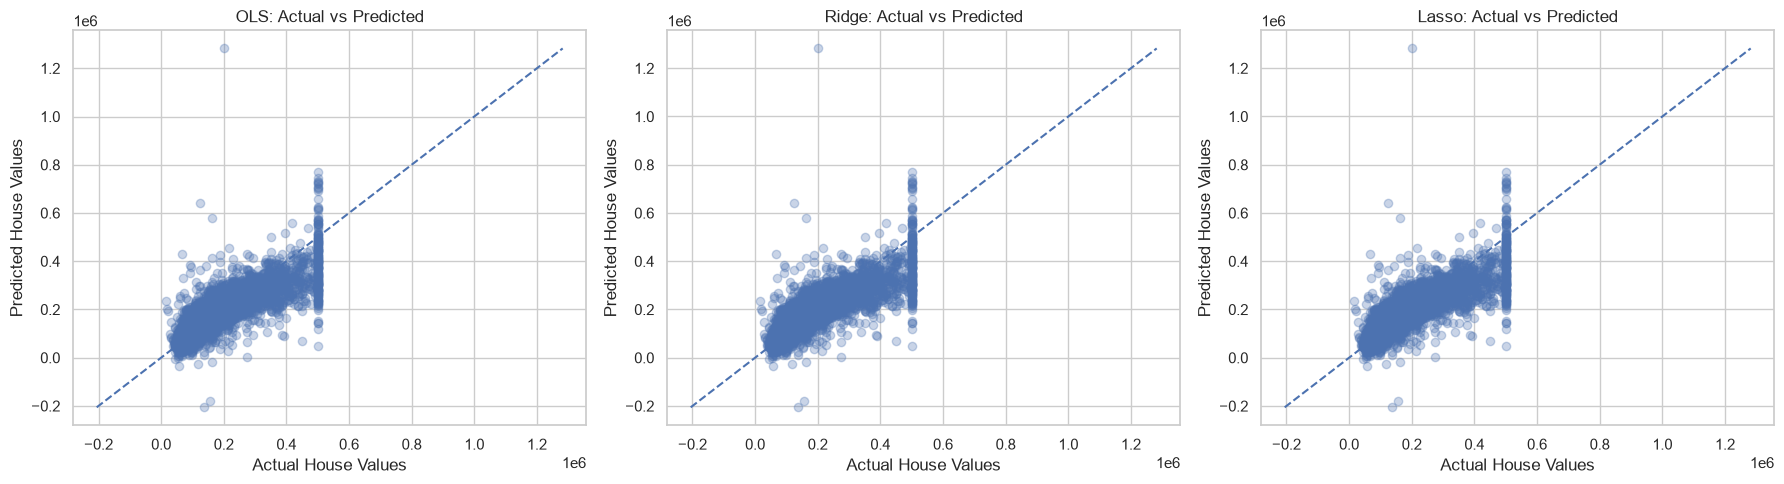

In [48]:
# ============================================
# 8.3 ACTUAL VS PREDICTED VALUES
# ============================================

import matplotlib.pyplot as plt

# Create subplots for all three models
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (model_name, y_pred) in zip(axes, model_predictions.items()):

    # Plot actual vs predicted values
    ax.scatter(
        y_test,
        y_pred,
        alpha=0.3
    )

    # Add reference line
    min_value = min(np.min(y_test), np.min(y_pred))
    max_value = max(np.max(y_test), np.max(y_pred))

    ax.plot(
        [min_value, max_value],
        [min_value, max_value],
        linestyle='--'
    )

    # Set plot labels and title
    ax.set_title(f'{model_name}: Actual vs Predicted')
    ax.set_xlabel('Actual House Values')
    ax.set_ylabel('Predicted House Values')
    ax.grid(True)

plt.tight_layout()
plt.show()

### 8.4 Residual Distribution Analysis

Residual distribution analysis is performed to understand the spread and distribution of prediction errors generated by each regression model.

Histograms with Kernel Density Estimation (KDE) curves are used to visualize the residual distributions.

A distribution centered around zero indicates that the model has relatively little average prediction bias.

The distribution also helps identify skewness, variability, and unusually large prediction errors.

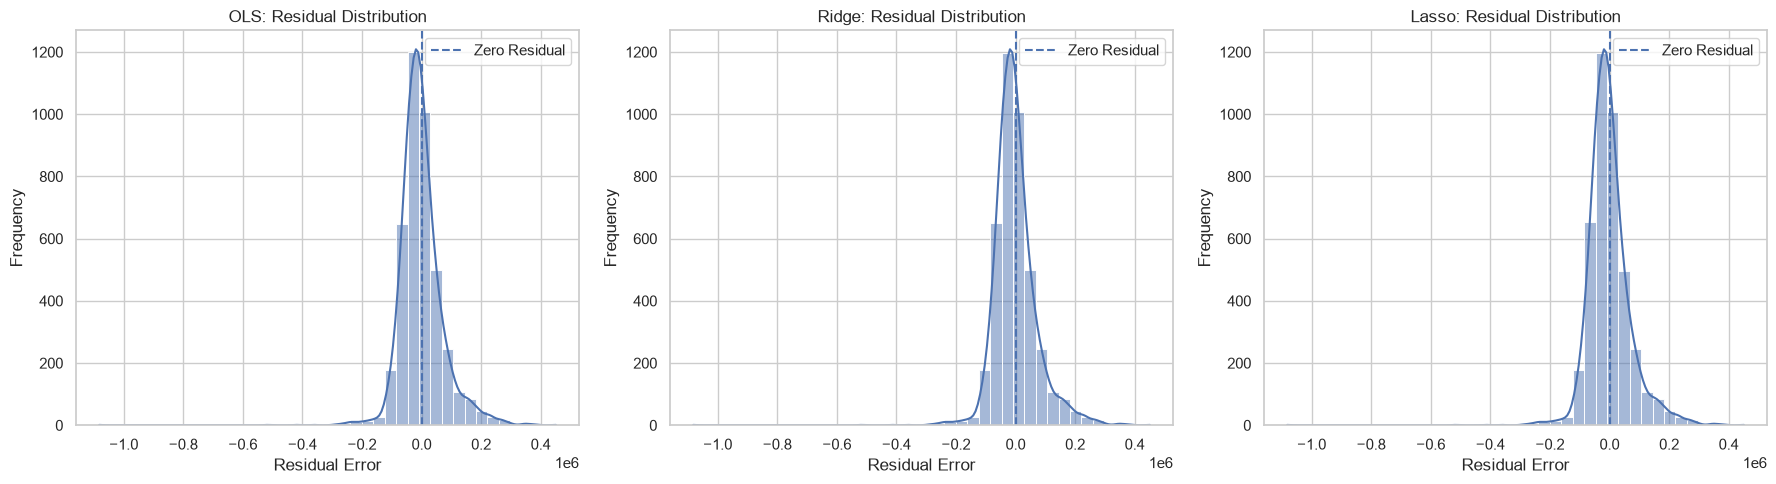

In [49]:
# ============================================
# 8.4 RESIDUAL DISTRIBUTION ANALYSIS
# ============================================

import seaborn as sns

# Create subplots
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (model_name, residuals) in zip(axes, model_residuals.items()):

    # Plot residual distribution
    sns.histplot(
        residuals,
        kde=True,
        bins=40,
        ax=ax
    )

    # Add zero reference line
    ax.axvline(
        0,
        linestyle='--',
        label='Zero Residual'
    )

    # Set plot labels and title
    ax.set_title(f'{model_name}: Residual Distribution')
    ax.set_xlabel('Residual Error')
    ax.set_ylabel('Frequency')
    ax.legend()
    ax.grid(True)

plt.tight_layout()
plt.show()

### 8.5 Residuals vs Predicted Values

Residuals vs Predicted plots are used to examine the relationship between prediction errors and predicted house values.

Scatter plots are created for all three regression models.

A horizontal reference line at zero represents the point where actual and predicted values are equal.

These plots help identify possible patterns in prediction errors, including non-linearity, heteroscedasticity, and unusually large residuals.

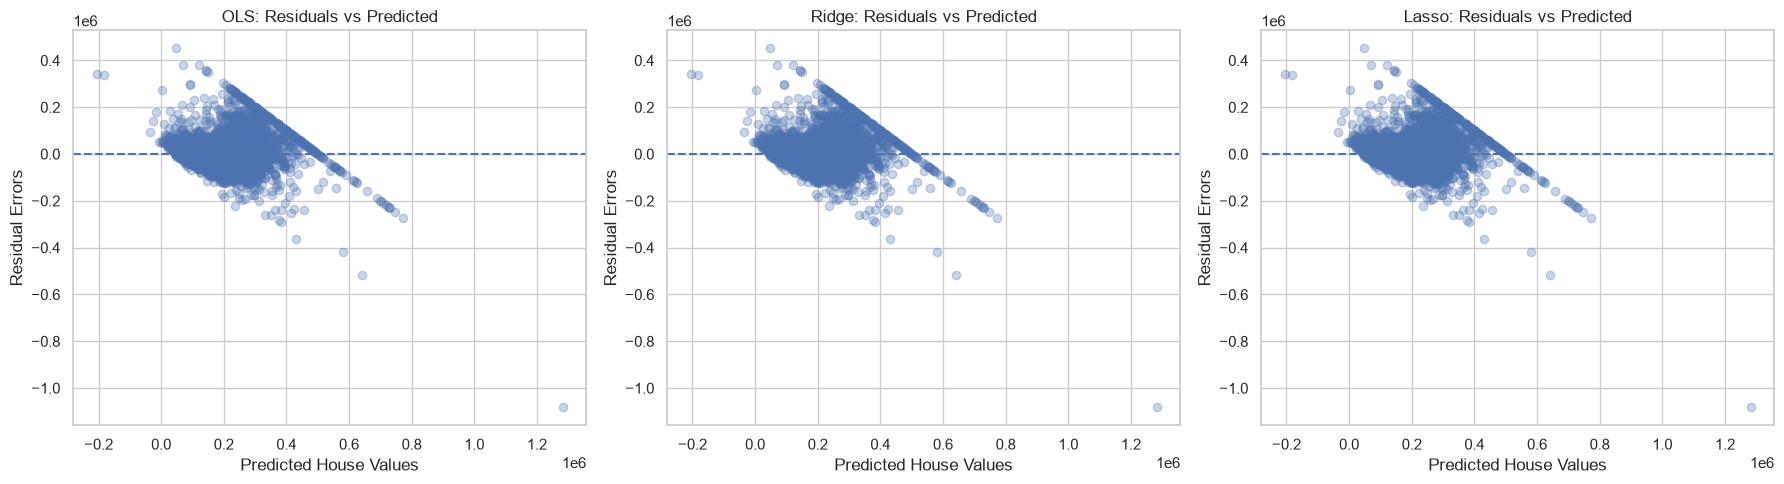

In [50]:
# ============================================
# 8.5 RESIDUALS VS PREDICTED VALUES
# ============================================

# Create subplots
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (model_name, y_pred) in zip(axes, model_predictions.items()):

    # Retrieve residuals
    residuals = model_residuals[model_name]

    # Plot predicted values against residuals
    ax.scatter(
        y_pred,
        residuals,
        alpha=0.3
    )

    # Add zero reference line
    ax.axhline(
        0,
        linestyle='--'
    )

    # Set plot labels and title
    ax.set_title(f'{model_name}: Residuals vs Predicted')
    ax.set_xlabel('Predicted House Values')
    ax.set_ylabel('Residual Errors')
    ax.grid(True)

plt.tight_layout()
plt.show()

### 8.6 Calculate Residual Statistics

Calculate statistical measures to compare the residual errors generated by the OLS, Ridge, and Lasso regression models.

The following statistical measures are considered:

- Mean Residual: Measures the average prediction bias.
- Median Residual: Represents the middle residual value.
- Residual Standard Deviation: Measures the spread of residual errors.
- Minimum Residual: Identifies the smallest residual value.
- Maximum Residual: Identifies the largest residual value.
- RMSE: Measures the overall magnitude of prediction errors.

These statistics provide a numerical comparison of the prediction errors generated by each model.

In [51]:
# ============================================
# 8.6 CALCULATE RESIDUAL STATISTICS
# ============================================

# Store residual statistics for each model
residual_statistics = {}

for model_name, residuals in model_residuals.items():

    # Calculate statistical measures
    residual_statistics[model_name] = {
        'Mean Residual': np.mean(residuals),
        'Median Residual': np.median(residuals),
        'Residual Std Dev': np.std(residuals),
        'Minimum Residual': np.min(residuals),
        'Maximum Residual': np.max(residuals),
        'RMSE': np.sqrt(np.mean(residuals ** 2))
    }

# Convert results into a DataFrame
residual_comparison = pd.DataFrame(residual_statistics).T

# Display residual statistics
print("Residual Statistics Comparison:")

display(residual_comparison.round(3))

Residual Statistics Comparison:


,Mean Residual,Median Residual,Residual Std Dev,Minimum Residual,Maximum Residual,RMSE
OLS,-632.991,-9684.822,72835.568,-1082355.080,451172.809,72838.318
Ridge,-631.289,-9686.053,72845.221,-1082253.185,451189.248,72847.956
Lasso,-631.708,-9683.491,72837.231,-1081974.039,451184.448,72839.970


### 8.7 Residual Analysis Summary

Summarize the residual analysis by examining the mean residual and standard deviation of each regression model.

The mean residual indicates the average direction of prediction errors, while the standard deviation represents the variability of residual errors.

This comparison helps identify possible prediction bias and differences in error distribution among the three regression models.

In [52]:
# ============================================
# 8.7 RESIDUAL ANALYSIS SUMMARY
# ============================================

print("RESIDUAL ANALYSIS SUMMARY")
print("=" * 50)

for model_name, residuals in model_residuals.items():

    # Calculate mean and standard deviation
    mean_residual = np.mean(residuals)
    std_residual = np.std(residuals)

    print(f"\nModel: {model_name}")
    print(f"Mean Residual: {mean_residual:.3f}")
    print(f"Residual Standard Deviation: {std_residual:.3f}")

    # Identify prediction tendency
    if mean_residual > 0:
        print("Prediction Tendency: Underprediction")

    elif mean_residual < 0:
        print("Prediction Tendency: Overprediction")

    else:
        print("Prediction Tendency: No Average Bias")

RESIDUAL ANALYSIS SUMMARY

Model: OLS
Mean Residual: -632.991
Residual Standard Deviation: 72835.568
Prediction Tendency: Overprediction

Model: Ridge
Mean Residual: -631.289
Residual Standard Deviation: 72845.221
Prediction Tendency: Overprediction

Model: Lasso
Mean Residual: -631.708
Residual Standard Deviation: 72837.231
Prediction Tendency: Overprediction


### 8.8 Overall Residual Analysis Interpretation

Residual analysis provides additional insights into the prediction performance of the OLS, Ridge, and Lasso regression models.

The Actual vs Predicted plots help evaluate how closely the predicted house values follow the actual values.

The residual distribution plots provide information about the spread and concentration of prediction errors.

The Residuals vs Predicted plots help identify possible patterns, non-linearity, and variations in prediction errors.

The residual statistics provide a numerical comparison of the average prediction bias and variability of errors across all three models.

Since the three regression models achieved similar evaluation metrics in Part 7, their residual analysis results are also expected to be broadly comparable.

Overall, residual analysis helps identify the strengths and limitations of the trained regression models and provides a better understanding of their prediction errors.